# Неделя 25. n8n: AI-агент с инструментами

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** спроектировать инструменты, traces и memory; пройти end-to-end сценарий и подготовить настоящий n8n AI Agent.

**Явный simulator:** Python planner маршрутизирует команды по фиксированным правилам, не использует LLM. В JSON находится реальный AI Agent node с моделью и tools; его live-запуск требует credentials и выбора доступной модели.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_25_n8n_ai_agents"
DATA = WEEK / "datasets"
SEED = 125
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. От workflow к agent

Workflow выполняет заданные шаги; агент может выбирать инструмент по контексту. Контракты инструментов должны быть узкими. Наш курс дает только чтение политики и сумму чисел, без отправки писем и изменений учетных записей.


,case_id,input,expected_tool,expected_status
0,G01,policy schedule,course_policy,ok
1,G02,policy homework,course_policy,ok
2,G03,policy unknown,course_policy,not_found
3,G04,"sum 12,5,3",sum_numbers,ok
4,G05,"sum 1,abc",sum_numbers,invalid_input
5,G06,send email to everyone,none,unsupported
6,G07,policy project,course_policy,ok
7,G08,"sum 0,-2,2",sum_numbers,ok


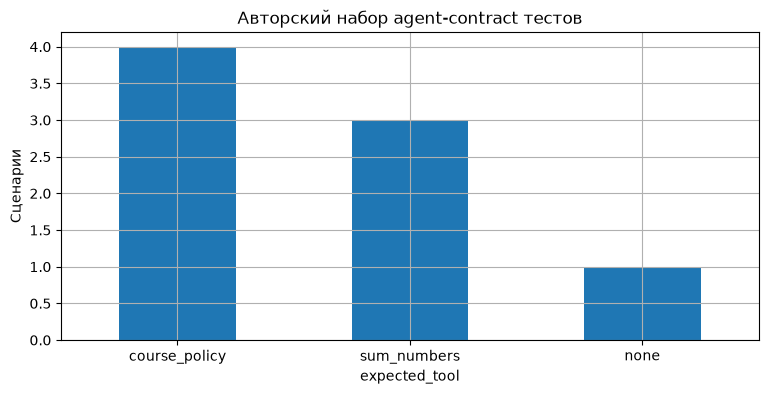

In [2]:
policies = json.loads((DATA / 'course_policies.json').read_text(encoding='utf-8'))
cases = pd.read_csv(DATA / 'agent_cases.csv', keep_default_na=False)
display(cases)
cases.expected_tool.value_counts().plot.bar(rot=0, title='Авторский набор agent-contract тестов')
plt.ylabel('Сценарии'); plt.show()
assert cases.case_id.is_unique


## 2. Read-only knowledge tool

Инструмент принимает один из трех ключей, возвращает текст и источник. При неизвестном ключе возвращается not_found. Аргумент не превращается в произвольный URL, SQL или код.


In [3]:
def course_policy(key):
    if not isinstance(key, str):
        return {'status': 'invalid_input'}
    record = policies.get(key.strip().lower())
    if record is None:
        return {'status': 'not_found'}
    return {'status': 'ok', 'key': key.strip().lower(), **record}
assert course_policy('homework')['status'] == 'ok'
assert course_policy('all_users')['status'] == 'not_found'
display(course_policy('project'))


{'status': 'ok',
 'key': 'project',
 'text': 'Учебная защита: 7 минут презентация и 3 минуты вопросы.',
 'source': 'synthetic_policy_project'}

## 3. Числовой инструмент без eval

Принимаем список до 10 конечных чисел. Приведение строки, диапазон и размер списка проверяются до вычисления. `eval` для входа пользователя запрещен в этой реализации: сложение не требует выполнения произвольного кода.


In [4]:
def sum_numbers(raw):
    try:
        parts = raw.split(',')
        if not 1 <= len(parts) <= 10 or any(not value.strip() for value in parts):
            return {'status': 'invalid_input'}
        values = [float(value.strip()) for value in parts]
    except (ValueError, AttributeError):
        return {'status': 'invalid_input'}
    if not all(math.isfinite(x) and abs(x) <= 1_000_000 for x in values):
        return {'status': 'invalid_input'}
    return {'status': 'ok', 'value': sum(values), 'count': len(values)}
assert sum_numbers('12,5,3')['value'] == 20
assert sum_numbers('1,abc')['status'] == 'invalid_input'
assert sum_numbers('nan')['status'] == 'invalid_input'
assert sum_numbers('0,-2,2')['value'] == 0


## 4. Прозрачный planner fixture

Команды `policy KEY` и `sum NUMBERS` нужны для точного offline-теста. В живом n8n LLM будет выбирать по естественному языку. Здесь planner возвращает структурированный план, который мы можем проверить до выполнения.


In [5]:
def plan(command):
    if command.startswith('policy '):
        return {'tool': 'course_policy', 'argument': command[7:]}
    if command.startswith('sum '):
        return {'tool': 'sum_numbers', 'argument': command[4:]}
    return {'tool': 'none', 'argument': None}
tools = {'course_policy': course_policy, 'sum_numbers': sum_numbers}
assert plan('send email')['tool'] == 'none'
display(plan('policy schedule'))


{'tool': 'course_policy', 'argument': 'schedule'}

## 5. Исполнение с allowlist и trace

Agent plan не равен разрешению. Executor проверяет допустимые имена tools и лимит шагов. Trace сохраняет наблюдаемые действия и результаты, а не скрытые внутренние рассуждения модели.


In [6]:
def run_agent(command, max_steps=2):
    trace = []
    if max_steps < 1:
        return {'status': 'step_limit', 'trace': trace, 'tool': 'none'}
    action = plan(command)
    trace.append({'event': 'plan', 'tool': action['tool']})
    if action['tool'] not in tools:
        return {'status': 'unsupported', 'tool': 'none', 'trace': trace}
    result = tools[action['tool']](action['argument'])
    trace.append({'event': 'tool_result', 'tool': action['tool'], 'status': result['status']})
    return {**result, 'tool': action['tool'], 'trace': trace}
display(run_agent('policy homework'))
assert run_agent('policy homework', max_steps=0)['status'] == 'step_limit'


{'status': 'ok',
 'key': 'homework',
 'text': 'Учебный срок домашней работы: Sunday 23:59.',
 'source': 'synthetic_policy_homework',
 'tool': 'course_policy',
 'trace': [{'event': 'plan', 'tool': 'course_policy'},
  {'event': 'tool_result', 'tool': 'course_policy', 'status': 'ok'}]}

## 6. End-to-end test на фиксированных кейсах

Проверим выбор инструмента и статус результата отдельно. «Агент ответил текстом» недостаточно: он мог не вызвать источник или вычислить число наугад. Все измерения относятся к детерминированному simulator.


In [7]:
results = []
for row in cases.itertuples():
    result = run_agent(row.input)
    results.append({'case_id': row.case_id, 'tool': result['tool'], 'status': result['status'],
                    'tool_correct': result['tool'] == row.expected_tool,
                    'status_correct': result['status'] == row.expected_status,
                    'trace_events': len(result['trace'])})
result_df = pd.DataFrame(results)
display(result_df)
assert result_df.tool_correct.all() and result_df.status_correct.all()


,case_id,tool,status,tool_correct,status_correct,trace_events
0,G01,course_policy,ok,True,True,2
1,G02,course_policy,ok,True,True,2
2,G03,course_policy,not_found,True,True,2
3,G04,sum_numbers,ok,True,True,2
4,G05,sum_numbers,invalid_input,True,True,2
5,G06,none,unsupported,True,True,1
6,G07,course_policy,ok,True,True,2
7,G08,sum_numbers,ok,True,True,2


## 7. Память сессии и source grounding

Храним три последних наблюдаемых действия по session_id. Локальный идентификатор — только механизм разделения памяти, а не доказанная аутентификация. Фактический ответ course_policy содержит source.


In [8]:
from collections import defaultdict, deque
sessions = defaultdict(lambda: deque(maxlen=3))
def session_run(session_id, command):
    result = run_agent(command)
    sessions[session_id].append({'input': command, 'result': result})
    return result
a = session_run('A', 'policy schedule')
b = session_run('B', 'sum 10,20')
assert a['source'] == policies['schedule']['source']
assert len(sessions['A']) == len(sessions['B']) == 1
assert sessions['A'][0]['input'] != sessions['B'][0]['input']


## 8. Метрики наблюдаемости

Считаем tool-success и failure distribution, среднее число trace-событий. Эти события — не число LLM tokens. У живого агента отдельно измеряются usage, tool latency и ошибки модели; симулятор не должен выдумывать эти величины.


,n,success_rate,avg_trace_events
tool,,,
course_policy,4,0.750000,2.0
none,1,0.000000,1.0
sum_numbers,3,0.666667,2.0


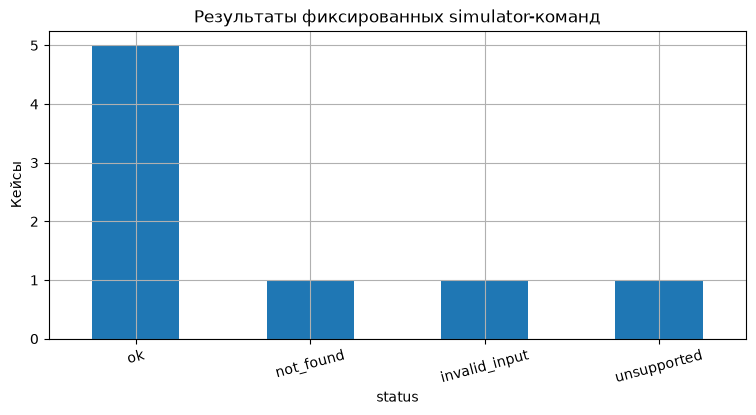

In [9]:
display(result_df.groupby('tool').agg(n=('status', 'size'), success_rate=('status', lambda x: x.eq('ok').mean()),
                                    avg_trace_events=('trace_events', 'mean')))
result_df.status.value_counts().plot.bar(rot=15, title='Результаты фиксированных simulator-команд')
plt.ylabel('Кейсы'); plt.show()


## 9. Проверка графа реального n8n agent

Chat Model, Memory и Tool подключаются через специальные ai_* связи. Обычного main-edge между tool и агентом недостаточно. В нашей заготовке есть два инструмента, память с session key и отдельный response checker.


In [10]:
wf = json.loads((WEEK / 'practice' / 'n8n_ai_agent_course_helper.json').read_text())
types = {n['type'] for n in wf['nodes']}
assert '@n8n/n8n-nodes-langchain.agent' in types
assert '@n8n/n8n-nodes-langchain.toolCode' in types
assert any('ai_tool' in links for links in wf['connections'].values())
assert any('ai_languageModel' in links for links in wf['connections'].values())
assert wf['active'] is False and all('credentials' not in node for node in wf['nodes'])
display(pd.DataFrame([{'name': n['name'], 'type': n['type'], 'version': n['typeVersion']} for n in wf['nodes']]))


,name,type,version
0,Course Chat,@n8n/n8n-nodes-langchain.chatTrigger,1.3
1,Course Agent,@n8n/n8n-nodes-langchain.agent,3.1
2,Select OpenAI Model,@n8n/n8n-nodes-langchain.lmChatOpenAi,1.3
3,Session Memory,@n8n/n8n-nodes-langchain.memoryBufferWindow,1.3
4,Course Policy,@n8n/n8n-nodes-langchain.toolCode,1.3
5,Sum Numbers,@n8n/n8n-nodes-langchain.toolCode,1.3
6,Validate Response,n8n-nodes-base.code,2.0


## 10. Реальный агент и ограничения

Следуйте N8N_AI_AGENT_LAB.md. На первом запуске выберите доступную модель и credential. Simple Memory подходит учебной одиночной instance; для queue mode документация предупреждает о несовместимости. Не называйте эти JSON exports протестированным production deployment.


In [11]:
print({'local_tools': 'passed', 'planner': 'deterministic_fixture', 'n8n_llm_agent': 'not_run'})


{'local_tools': 'passed', 'planner': 'deterministic_fixture', 'n8n_llm_agent': 'not_run'}


## Источники и следующий шаг

- [n8n: AI Agent](https://docs.n8n.io/integrations/builtin/cluster-nodes/root-nodes/n8n-nodes-langchain.agent/)
- [n8n: Custom Code Tool](https://docs.n8n.io/integrations/builtin/cluster-nodes/sub-nodes/n8n-nodes-langchain.toolcode/)
- [n8n: Simple Memory](https://docs.n8n.io/integrations/builtin/cluster-nodes/sub-nodes/n8n-nodes-langchain.memorybufferwindow/)
- [n8n: OpenAI Chat Model](https://docs.n8n.io/integrations/builtin/cluster-nodes/sub-nodes/n8n-nodes-langchain.lmchatopenai/)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
